In [15]:
import pandas as pd

# Load the uploaded CSV dataset
file_path = "/content/customer_churn_dataset-testing-master.csv"

df = pd.read_csv(file_path)

# Display dataset information
print("Dataset loaded successfully!")
print("Total rows and columns:", df.shape)

# Display the first five rows
display(df.head())

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

Dataset loaded successfully!
Total rows and columns: (64374, 12)


,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22,Female,25,14,4,27,Basic,Monthly,598,9,1
1,2,41,Female,28,28,7,13,Standard,Monthly,584,20,0
2,3,47,Male,27,10,2,29,Premium,Annual,757,21,0
3,4,35,Male,9,12,5,17,Premium,Quarterly,232,18,0
4,5,53,Female,58,24,9,2,Standard,Annual,533,18,0



Column names:
['CustomerID', 'Age', 'Gender', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Subscription Type', 'Contract Length', 'Total Spend', 'Last Interaction', 'Churn']


In [16]:
# Display all column names
print("Dataset Columns:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Columns:
['CustomerID', 'Age', 'Gender', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Subscription Type', 'Contract Length', 'Total Spend', 'Last Interaction', 'Churn']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64374 entries, 0 to 64373
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   CustomerID         64374 non-null  int64 
 1   Age                64374 non-null  int64 
 2   Gender             64374 non-null  object
 3   Tenure             64374 non-null  int64 
 4   Usage Frequency    64374 non-null  int64 
 5   Support Calls      64374 non-null  int64 
 6   Payment Delay      64374 non-null  int64 
 7   Subscription Type  64374 non-null  object
 8   Contract Length    64374 non-null  object
 9   Total Spend        64374 non-null  int64 
 10  Last Interaction   64374 non-null  int64 
 11  Churn              64374 non-null  int64 
dtypes: int64(9

In [17]:
# CUSTOMER CHURN ANALYSIS USING PYTHON

# Total number of customers
total_customers = df["CustomerID"].nunique()

# Count churned and retained customers
churn_counts = df["Churn"].value_counts()

# Calculate churn rate
churned_customers = (df["Churn"] == 1).sum()
retained_customers = (df["Churn"] == 0).sum()

churn_rate = (churned_customers / len(df)) * 100

# Calculate total and average customer spending
total_spend = df["Total Spend"].sum()
average_spend = df["Total Spend"].mean()

# Display results
print("CUSTOMER CHURN ANALYSIS")
print("-" * 35)

print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Retained Customers:", retained_customers)
print(f"Churn Rate: {churn_rate:.2f}%")
print(f"Total Spend: {total_spend:,.2f}")
print(f"Average Customer Spend: {average_spend:,.2f}")

CUSTOMER CHURN ANALYSIS
-----------------------------------
Total Customers: 64374
Churned Customers: 30493
Retained Customers: 33881
Churn Rate: 47.37%
Total Spend: 34,827,839.00
Average Customer Spend: 541.02


In [18]:
# CHURN ANALYSIS BY SUBSCRIPTION TYPE

subscription_analysis = df.groupby("Subscription Type").agg(
    Total_Customers=("CustomerID", "count"),
    Churned_Customers=("Churn", "sum"),
    Average_Spend=("Total Spend", "mean")
)

subscription_analysis["Churn_Rate_%"] = (
    subscription_analysis["Churned_Customers"]
    / subscription_analysis["Total_Customers"]
) * 100

# Display results
print("Churn Analysis by Subscription Type")
display(subscription_analysis.round(2))

Churn Analysis by Subscription Type


,Total_Customers,Churned_Customers,Average_Spend,Churn_Rate_%
Subscription Type,,,,
Basic,21451,10356,540.91,48.28
Premium,21421,9960,543.58,46.50
Standard,21502,10177,538.59,47.33


Churn Analysis by Payment Delay


,Total_Customers,Churned_Customers,Churn_Rate_%
Payment Delay,,,
0,1594,153,9.60
1,1539,147,9.55
2,1531,178,11.63
3,1543,166,10.76
4,1588,156,9.82
5,1568,154,9.82
6,1541,136,8.83
7,1539,166,10.79
8,1559,154,9.88


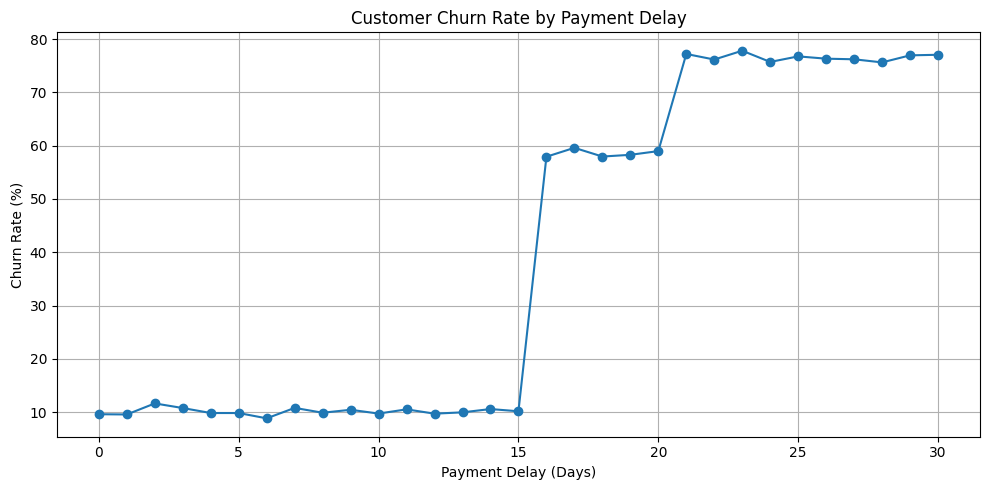

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

# Analyze churn by payment delay
payment_analysis = df.groupby("Payment Delay").agg(
    Total_Customers=("CustomerID", "count"),
    Churned_Customers=("Churn", "sum")
)

payment_analysis["Churn_Rate_%"] = (
    payment_analysis["Churned_Customers"]
    / payment_analysis["Total_Customers"]
) * 100

# Display the first 10 payment-delay categories
print("Churn Analysis by Payment Delay")
display(payment_analysis.head(10).round(2))

# Create a chart
payment_analysis["Churn_Rate_%"].plot(
    kind="line",
    figsize=(10, 5),
    marker="o"
)

plt.title("Customer Churn Rate by Payment Delay")
plt.xlabel("Payment Delay (Days)")
plt.ylabel("Churn Rate (%)")
plt.grid(True)
plt.tight_layout()
plt.show()

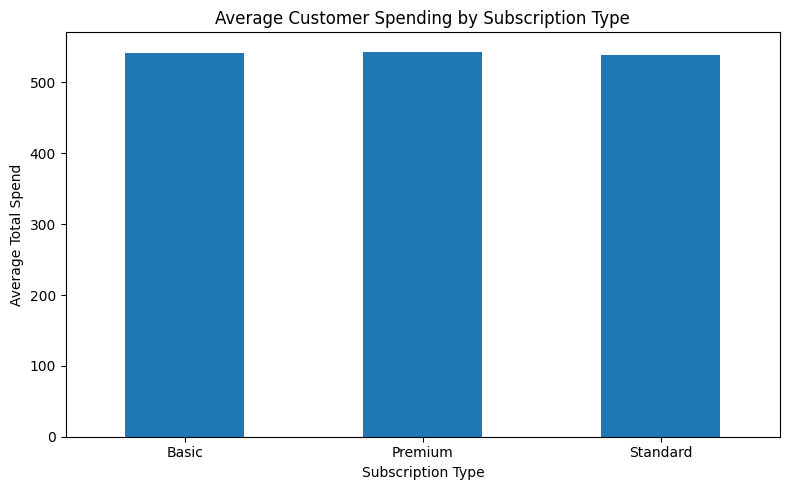

In [20]:
import matplotlib.pyplot as plt

# Calculate average spending by subscription type
spending = df.groupby("Subscription Type")["Total Spend"].mean()

# Create bar chart
plt.figure(figsize=(8, 5))
spending.plot(kind="bar")

plt.title("Average Customer Spending by Subscription Type")
plt.xlabel("Subscription Type")
plt.ylabel("Average Total Spend")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()